# 02 - Gait biomechanics from the instrumented treadmill

**Question.** How does walking change between 0.5 and 1.0 m/s, and how large are those changes relative
to the differences between people? The force plates are the reference instrument for timing and loading,
so this notebook also defines the measurements that the wearable sensors are judged against in notebook 03.

**Method.** Gait events come from the vertical force under each belt (contact while the plate carries
more than 5 % of body weight, after re-zeroing each plate). Forces are expressed in body weights (BW) and
stance phase is time-normalised to 101 points. Speed effects are estimated with linear mixed models
(random intercept per participant), so each participant serves as their own control across the three
speeds; p-values are Holm-adjusted across the feature family. Whole-waveform differences are tested with
a paired cluster-based permutation test over the stance phase.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mgait import config as C, features as F, gait as G, plotting as P, stats as S

P.use_style()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)
fp = pd.read_parquet(C.CACHE / "fp_strides.parquet")
curves = dict(np.load(C.CACHE / "fp_curves.npz"))
T = F.trial_table()
T.to_parquet(C.TABLES / "trial_features.parquet")
ok = fp["qc_ok"].to_numpy()
print(f"{int(ok.sum())} strides from {fp.groupby(['subject', 'speed']).ngroups} trials, {fp.subject.nunique()} participants; "
      f"median {fp.groupby(['subject', 'speed']).size().median():.0f} strides per trial")

15574 strides from 173 trials, 59 participants; median 92 strides per trial


## 1. Event detection on the force plates

Six seconds of one trial: each belt alternates between loaded (stance) and unloaded (swing), and the
periods where both belts are loaded are double support. Detected heel strikes and toe-offs are marked.

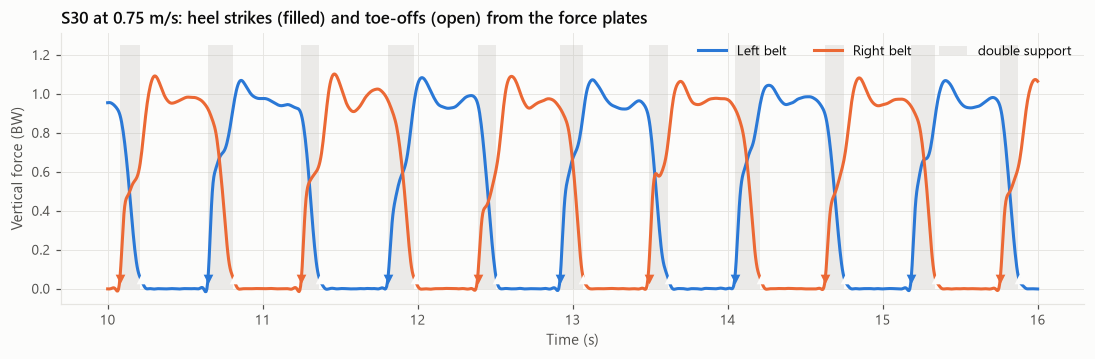

In [2]:
tr = G.fp_process("S30", "0.75")
fig, ax = plt.subplots(figsize=(12, 3.2))
w = (tr.t >= 10) & (tr.t <= 16)
for side, col in P.SIDE_COLORS.items():
    ax.plot(tr.t[w], tr.z[side][w] / tr.bw_n, color=col, label=f"{'Left' if side == 'L' else 'Right'} belt")
    hs = tr.events.hs[side][(tr.events.hs[side] >= 10) & (tr.events.hs[side] <= 16)]
    to = tr.events.to[side][(tr.events.to[side] >= 10) & (tr.events.to[side] <= 16)]
    ax.scatter(hs, np.full(len(hs), 0.05), marker="v", s=40, color=col, zorder=3)
    ax.scatter(to, np.full(len(to), 0.05), marker="^", s=40, color=col, zorder=3, facecolor=P.SURFACE)
both = (tr.z["L"] > 0.05 * tr.bw_n) & (tr.z["R"] > 0.05 * tr.bw_n)
ax.fill_between(tr.t[w], 0, 1.25, where=both[w], color=P.NEUTRAL, alpha=0.25, linewidth=0, label="double support")
ax.set_xlabel("Time (s)"); ax.set_ylabel("Vertical force (BW)")
ax.set_title("S30 at 0.75 m/s: heel strikes (filled) and toe-offs (open) from the force plates")
ax.legend(ncol=3, loc="upper right")
P.save(fig, "02_events_example")
plt.show()

## 2. Spatiotemporal adaptation to speed

Each grey line is one participant; the coloured points are the median at each speed.

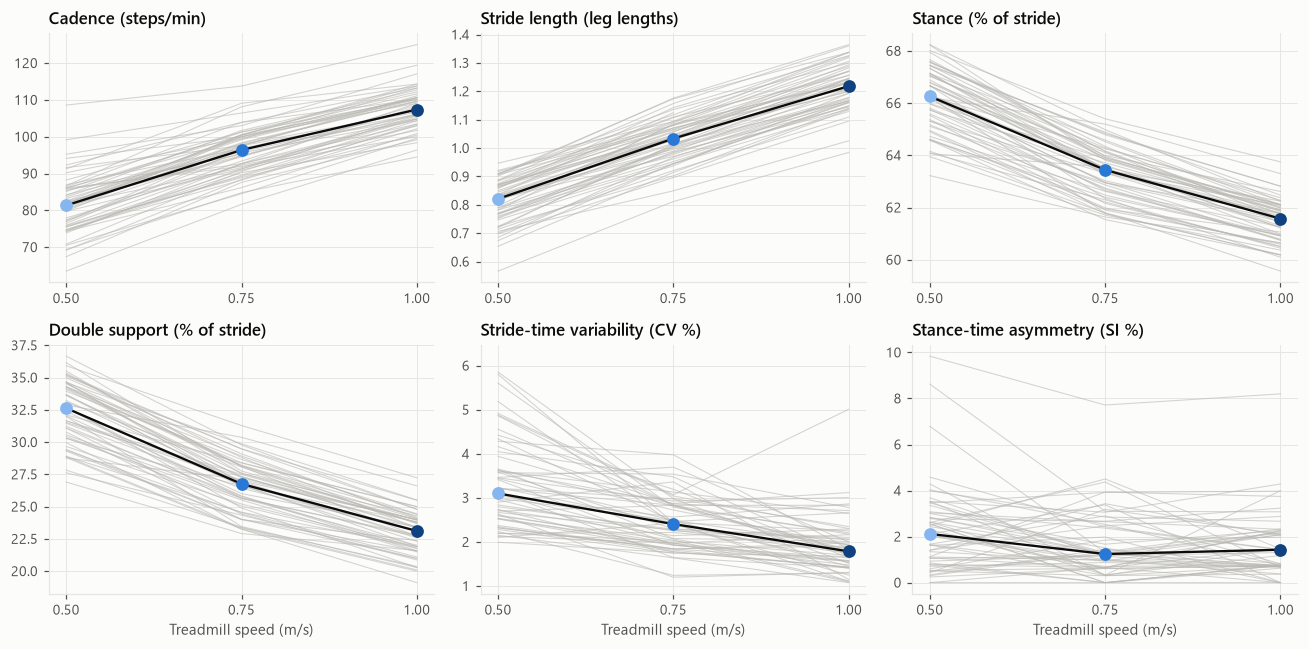

In [3]:
panels = [("fp_cadence", "Cadence (steps/min)"), ("fp_stride_length_norm", "Stride length (leg lengths)"),
          ("fp_stance_pct", "Stance (% of stride)"), ("fp_double_support_pct", "Double support (% of stride)"),
          ("fp_stride_cv", "Stride-time variability (CV %)"), ("fp_stance_si", "Stance-time asymmetry (SI %)")]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, (col, lab) in zip(axes.flat, panels):
    piv = T.pivot(index="subject", columns="speed", values=col)[C.SPEEDS]
    for _, r in piv.iterrows():
        ax.plot([0.5, 0.75, 1.0], r.values, color=P.NEUTRAL, lw=0.7, alpha=0.6)
    for s in C.SPEEDS:
        ax.scatter(C.SPEED_MS[s], piv[s].median(), s=70, color=P.SPEED_COLORS[s], zorder=3)
    ax.plot([0.5, 0.75, 1.0], piv.median().values, color=P.INK, lw=1.5, zorder=2)
    ax.set_xticks([0.5, 0.75, 1.0]); ax.set_title(lab)
for ax in axes[1]:
    ax.set_xlabel("Treadmill speed (m/s)")
fig.tight_layout()
P.save(fig, "02_spatiotemporal")
plt.show()

In [4]:
fp_feats = ["fp_cadence", "fp_stride_length_norm", "fp_stance_pct", "fp_double_support_pct", "fp_stride_cv",
            "fp_stance_si", "fp_fz_peak1", "fp_fz_valley", "fp_fz_peak2", "fp_loading_rate", "fp_fz_impulse",
            "fp_fy_brake_peak", "fp_fy_prop_peak", "fp_fy_brake_impulse", "fp_fy_prop_impulse", "fp_fx_range"]
eff = S.speed_effects(T, fp_feats)
eff.to_csv(C.TABLES / "fp_speed_effects.csv", index=False)
display(eff.set_index("feature")[["n_subjects", "mean_0.5", "mean_1.0", "per_0.5ms", "ci_lo", "ci_hi", "std_effect", "p_holm"]])

,n_subjects,mean_0.5,mean_1.0,per_0.5ms,ci_lo,ci_hi,std_effect,p_holm
feature,,,,,,,,
fp_cadence,59,81.474,107.508,26.095,24.984,27.206,2.064,0.000e+00
fp_stride_length_norm,59,0.809,1.217,0.409,0.397,0.420,2.210,0.000e+00
fp_stance_pct,59,66.205,61.481,-4.700,-4.921,-4.478,-2.117,0.000e+00
fp_double_support_pct,59,32.364,22.936,-9.377,-9.799,-8.956,-2.118,0.000e+00
fp_stride_cv,59,3.339,1.914,-1.446,-1.674,-1.219,-1.445,4.126e-35
fp_stance_si,59,2.385,1.619,-0.763,-1.177,-0.348,-0.466,6.208e-04
fp_fz_peak1,59,1.043,1.030,-0.013,-0.022,-0.003,-0.394,7.854e-03
fp_fz_valley,59,0.932,0.846,-0.086,-0.092,-0.081,-2.045,5.078e-209
fp_fz_peak2,59,0.999,1.043,0.045,0.038,0.052,1.409,2.776e-35


All sixteen force-plate features change with speed after Holm correction. Between 0.5 and 1.0 m/s:

* cadence rises from 81 to 108 steps/min and stride length from 0.81 to 1.22 leg lengths;
* stance shortens from 66 % to 61 % of the stride and double support from 32 % to 23 %;
* braking and propulsive force peaks roughly double (0.07 to 0.14 BW and 0.07 to 0.16 BW) and the vertical
  loading rate doubles (3.2 to 6.3 BW/s);
* stride-time variability falls from 3.3 % to 1.9 %.

The first vertical force peak is the exception in magnitude: it barely moves (1.04 to 1.03 BW). At these
slow speeds the extra demand of faster walking appears in the horizontal forces, the loading *rate* and the
deepening mid-stance unloading rather than in a larger impact peak.

## 3. How do people walk faster: longer strides or quicker steps?

Speed is the product of step frequency and step length, so log(speed) = log(cadence) + log(step length).
The share of the increase in log speed carried by each term shows the strategy.

Share of the speed increase carried by cadence: median 0.41 (IQR 0.36 to 0.47), n = 56
Participants relying more on cadence than on stride length: 8 of 56


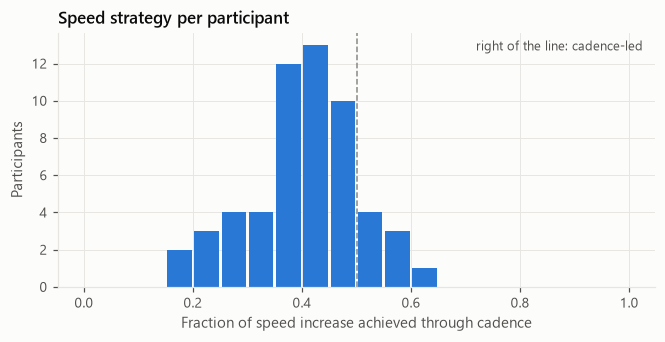

In [5]:
d = T.dropna(subset=["fp_cadence", "fp_stride_length"]).copy()
d["log_v"], d["log_cad"], d["log_len"] = np.log(d["speed_ms"]), np.log(d["fp_cadence"]), np.log(d["fp_stride_length"])
rows = []
for subj, g in d.groupby("subject"):
    if g["speed"].nunique() < 3:
        continue
    bv = np.polyfit(g["log_v"], g["log_cad"], 1)[0]
    rows.append({"subject": subj, "cadence_share": bv, "length_share": 1 - bv})
share = pd.DataFrame(rows)
print(f"Share of the speed increase carried by cadence: median {share.cadence_share.median():.2f} "
      f"(IQR {share.cadence_share.quantile(.25):.2f} to {share.cadence_share.quantile(.75):.2f}), n = {len(share)}")
print(f"Participants relying more on cadence than on stride length: {(share.cadence_share > 0.5).sum()} of {len(share)}")
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(share["cadence_share"], bins=np.arange(0, 1.05, 0.05), color=P.CAT[0], rwidth=0.9)
ax.axvline(0.5, color=P.MUTED, ls="--", lw=1)
ax.set_xlabel("Fraction of speed increase achieved through cadence")
ax.set_ylabel("Participants")
ax.set_title("Speed strategy per participant")
P.note(ax, "right of the line: cadence-led", "upper right")
P.save(fig, "02_speed_strategy")
plt.show()

## 4. Ground reaction force waveforms

Mean stance-phase forces per speed (participant means, then averaged; shaded band = between-participant SD).

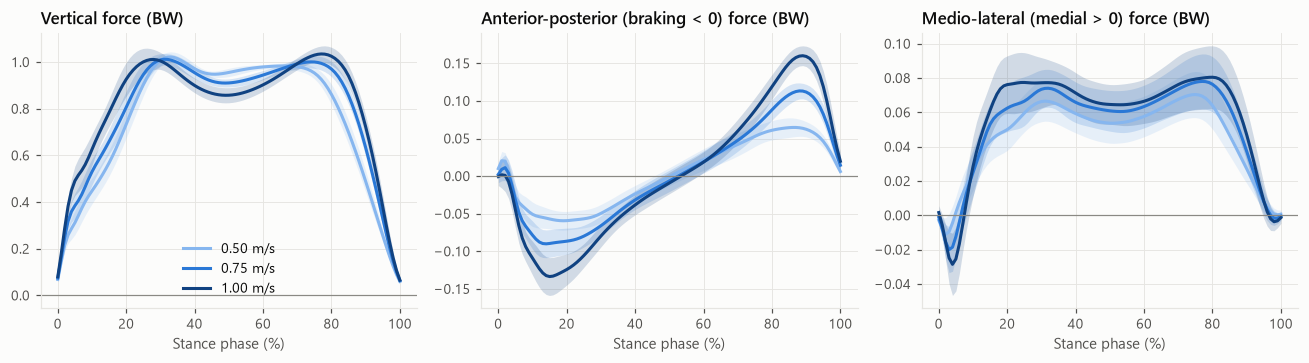

In [6]:
fp_ok = fp[ok].reset_index(drop=True)
subj_curves = {}
for comp in ("Fz", "Fy", "Fx"):
    X = pd.DataFrame(curves[comp][ok])
    X["subject"], X["speed"] = fp_ok["subject"].values, fp_ok["speed"].values
    subj_curves[comp] = X.groupby(["subject", "speed"]).mean()
x = np.arange(101)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, comp, lab in zip(axes, ("Fz", "Fy", "Fx"), ("Vertical", "Anterior-posterior (braking < 0)", "Medio-lateral (medial > 0)")):
    for s in C.SPEEDS:
        M = subj_curves[comp].xs(s, level="speed").to_numpy()
        P.band(ax, x, M.mean(0), M.std(0), P.SPEED_COLORS[s], P.SPEED_LABEL[s])
    ax.set_title(f"{lab} force (BW)")
    ax.set_xlabel("Stance phase (%)")
    ax.axhline(0, color=P.MUTED, lw=0.8)
axes[0].legend(loc="lower center")
fig.tight_layout()
P.save(fig, "02_grf_curves")
plt.show()

Fz [(0, 29, 0.0), (31, 68, 0.0), (70, 100, 0.0)]


Fy [(0, 60, 0.0), (65, 100, 0.0)]


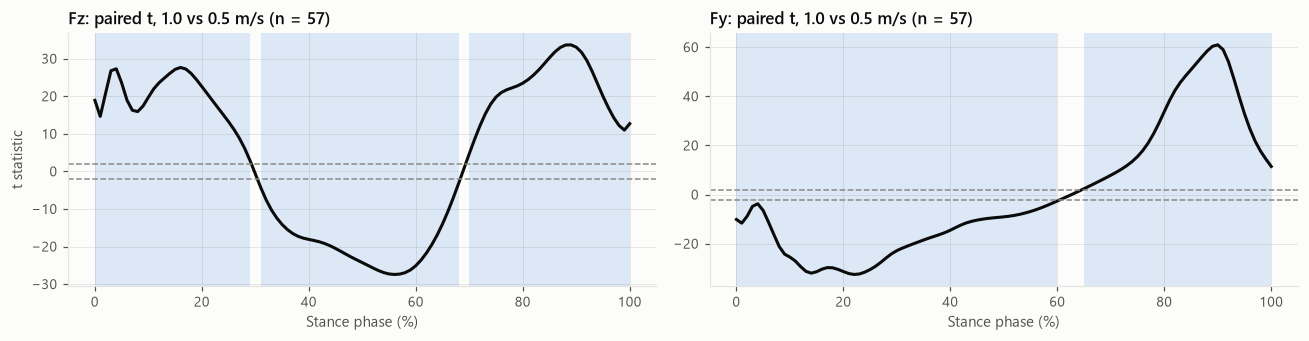

In [7]:
res = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for ax, comp in zip(axes, ("Fz", "Fy")):
    A = subj_curves[comp].xs("1", level="speed")
    B = subj_curves[comp].xs("0.5", level="speed")
    common = A.index.intersection(B.index)
    r = S.paired_cluster_test(A.loc[common].to_numpy(), B.loc[common].to_numpy(), n_perm=5000)
    res[comp] = r
    ax.plot(x, r["t"], color=P.INK)
    ax.axhline(r["threshold"], color=P.MUTED, ls="--", lw=1); ax.axhline(-r["threshold"], color=P.MUTED, ls="--", lw=1)
    for c in r["clusters"]:
        if c["p"] < 0.05:
            ax.axvspan(c["start"], c["end"], color=P.CAT[0], alpha=0.15, linewidth=0)
    ax.set_title(f"{comp}: paired t, 1.0 vs 0.5 m/s (n = {len(common)})")
    ax.set_xlabel("Stance phase (%)")
    print(comp, [(c["start"], c["end"], round(c["p"], 4)) for c in r["clusters"]])
axes[0].set_ylabel("t statistic")
fig.tight_layout()
P.save(fig, "02_grf_spm")
plt.show()

Shaded regions are stance intervals where the 1.0 and 0.5 m/s waveforms differ (cluster-level p < 0.05,
5,000 sign-flip permutations). Faster walking deepens the mid-stance unloading of the vertical force and
raises push-off, turning the nearly flat vertical profile of very slow walking into the classic double
hump. In the anterior-posterior direction, braking early in stance and propulsion late in stance both grow
over most of the stance phase.

## 5. Body mass index

Earlier work on this cohort (force plates only) reported BMI-specific adaptations. Here BMI is tested as
a continuous covariate with speed and sex in the same mixed model, which avoids arbitrary category cut-offs
in a sample of 59. Forces are already in body weights, so a BMI effect means loading *beyond* what body
weight alone would predict.

,per_5_bmi,ci_lo,ci_hi,std_effect,std_lo,std_hi,p,p_holm
feature,,,,,,,,
fp_cadence,-1.641e+00,-3.337e+00,5.586e-02,-0.130,-0.264,0.004,5.804e-02,3.482e-01
fp_stride_length_norm,1.171e-02,-8.613e-03,3.203e-02,0.063,-0.047,0.173,2.588e-01,1.000e+00
fp_stance_pct,5.363e-01,2.999e-01,7.727e-01,0.242,0.135,0.348,8.745e-06,7.871e-05
fp_double_support_pct,1.082e+00,6.101e-01,1.555e+00,0.244,0.138,0.351,7.051e-06,7.051e-05
fp_stride_cv,-1.207e-02,-1.917e-01,1.675e-01,-0.012,-0.192,0.167,8.952e-01,1.000e+00
fp_fz_peak1,-2.725e-03,-9.303e-03,3.853e-03,-0.085,-0.291,0.120,4.168e-01,1.000e+00
fp_loading_rate,-3.636e-01,-5.480e-01,-1.792e-01,-0.231,-0.348,-0.114,1.111e-04,8.889e-04
fp_fy_brake_peak,-3.973e-03,-8.082e-03,1.364e-04,-0.115,-0.233,0.004,5.811e-02,3.482e-01
fp_fy_prop_peak,4.662e-04,-2.375e-03,3.307e-03,0.012,-0.061,0.085,7.478e-01,1.000e+00


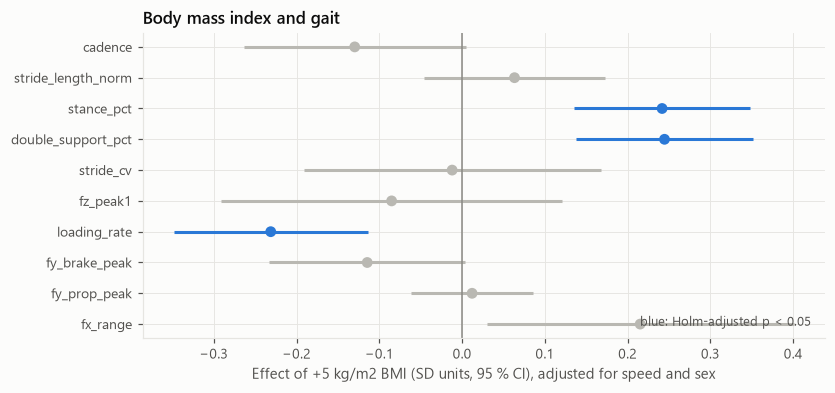

In [8]:
key = ["fp_cadence", "fp_stride_length_norm", "fp_stance_pct", "fp_double_support_pct", "fp_stride_cv",
       "fp_fz_peak1", "fp_loading_rate", "fp_fy_brake_peak", "fp_fy_prop_peak", "fp_fx_range"]
rows = []
for f in key:
    dd = T[["subject", "speed_ms", "bmi", "sex", f]].dropna().rename(columns={f: "y"})
    r = S.mixed_model(dd, "y ~ speed_ms + bmi + C(sex)")
    b, (lo, hi) = r.params["bmi"], r.conf_int().loc["bmi"]
    sd = dd["y"].std()
    rows.append({"feature": f, "per_5_bmi": 5 * b, "ci_lo": 5 * lo, "ci_hi": 5 * hi,
                 "std_effect": 5 * b / sd, "std_lo": 5 * lo / sd, "std_hi": 5 * hi / sd, "p": r.pvalues["bmi"]})
bmi = pd.DataFrame(rows)
bmi["p_holm"] = S.holm(bmi["p"].to_numpy())
bmi.to_csv(C.TABLES / "fp_bmi_effects.csv", index=False)
display(bmi.set_index("feature"))

fig, ax = plt.subplots(figsize=(8, 3.6))
yy = np.arange(len(bmi))[::-1]
sig = bmi["p_holm"] < 0.05
ax.hlines(yy, bmi["std_lo"], bmi["std_hi"], color=np.where(sig, P.CAT[0], P.NEUTRAL), lw=2)
ax.scatter(bmi["std_effect"], yy, s=50, color=np.where(sig, P.CAT[0], P.NEUTRAL), zorder=3)
P.note(ax, "blue: Holm-adjusted p < 0.05", "lower right")
ax.axvline(0, color=P.MUTED, lw=1)
ax.set_yticks(yy, [f.replace("fp_", "") for f in bmi["feature"]])
ax.set_xlabel("Effect of +5 kg/m2 BMI (SD units, 95 % CI), adjusted for speed and sex")
ax.set_title("Body mass index and gait")
P.save(fig, "02_bmi_effects")
plt.show()

## 6. Summary

* **Timing adapts most.** From 0.5 to 1.0 m/s cadence rises 32 % and stride length 50 %; stance and double
  support shorten by 5 and 9 percentage points. The standardised effects of speed exceed two
  between-trial standard deviations for the main timing variables.
* **Speed is gained mainly through longer strides.** For the median participant 59 % of the increase in
  speed comes from stride length and 41 % from cadence; only 8 of 56 participants are cadence-led.
* **Loading changes shape rather than peak height.** Horizontal force peaks and the loading rate double,
  the vertical waveform develops its mid-stance dip, and the first vertical peak stays near 1.03 BW.
  Cluster-based permutation tests locate the differences over almost the whole stance phase.
* **Slow walking is less regular.** Stride-time variability is 75 % higher at 0.5 m/s than at 1.0 m/s.
* **Higher BMI means a more cautious gait, not a harsher one.** Adjusted for speed and sex, each +5 kg/m2
  of BMI adds 0.5 percentage points of stance, 1.1 points of double support and lowers the loading rate by
  0.36 BW/s (all Holm-adjusted p < 0.001). Relative to body weight, heavier participants load the limb
  more slowly. Absolute joint loads still scale with mass; this result concerns force per kilogram.

These force-plate measurements are the reference for the wearable comparison in notebook 03.